In [2]:

from google.colab import files
import pandas as pd
import io

# Upload CSV file
uploaded = files.upload()

# Read uploaded CSV
file_name = next(iter(uploaded.keys()))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display basic information
print("File name:", file_name)
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Saving greenhouse_dataset.csv to greenhouse_dataset.csv
File name: greenhouse_dataset.csv
Dataset shape: (130195, 37)

First 5 rows:


,Unnamed: 0,F1,F2,F3,F4,H1,H10,H11,H12,H2,...,W7,W8,W9,AVGHumidityInside,HumidityOutside,L1,MeanInsideTemp,OutsideTemp,WS1,DateTime
0,0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,81.0,100.0,0.0,18.1,0.0,2.0,2023-12-19 00:00:00
1,1,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,80.9,100.0,0.0,18.1,0.0,3.0,2023-12-19 00:02:00
2,2,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,81.2,100.0,0.0,18.2,0.0,4.0,2023-12-19 00:04:00
3,3,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,80.9,100.0,0.0,18.2,0.1,3.0,2023-12-19 00:05:00
4,4,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,80.9,100.0,0.0,18.2,0.0,3.0,2023-12-19 00:07:00



Column names:
['Unnamed: 0', 'F1', 'F2', 'F3', 'F4', 'H1', 'H10', 'H11', 'H12', 'H2', 'H3', 'H4', 'H5', 'H6', 'H7', 'H8', 'H9', 'W1', 'W10', 'W11', 'W12', 'W16', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9', 'AVGHumidityInside', 'HumidityOutside', 'L1', 'MeanInsideTemp', 'OutsideTemp', 'WS1', 'DateTime']


In [3]:
#  Dataset Quality Assessment

import pandas as pd
import numpy as np

# 1. Convert DateTime column
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")

# 2. Dataset information
print("DATASET INFORMATION")
print("-" * 50)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Date range:", df["DateTime"].min(), "to", df["DateTime"].max())

# 3. Missing values
print("\nMISSING VALUES")
print("-" * 50)
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percent": missing_percent.round(2)
})

display(missing_report[missing_report["Missing_Count"] > 0])

# 4. Duplicate records
print("\nDUPLICATE RECORDS")
print("-" * 50)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["DateTime"].duplicated().sum())

# 5. Data types
print("\nDATA TYPES")
print("-" * 50)
display(df.dtypes.to_frame("Data_Type"))

# 6. Statistical summary
print("\nSTATISTICAL SUMMARY")
print("-" * 50)
display(df.describe().T.round(2))

# 7. Check invalid DateTime values
print("\nINVALID DATETIME VALUES")
print("-" * 50)
print("Invalid DateTime:", df["DateTime"].isna().sum())

DATASET INFORMATION
--------------------------------------------------
Rows: 130195
Columns: 37
Date range: 2023-12-19 00:00:00 to 2024-05-25 09:02:00

MISSING VALUES
--------------------------------------------------


,Missing_Count,Missing_Percent
W1,1,0.0
W10,3,0.0
W11,1,0.0
W12,1,0.0
W2,2,0.0
W3,1,0.0
W4,1,0.0
W6,2,0.0
W7,1,0.0
W9,1,0.0



DUPLICATE RECORDS
--------------------------------------------------
Duplicate rows: 0
Duplicate timestamps: 0

DATA TYPES
--------------------------------------------------


,Data_Type
Unnamed: 0,int64
F1,float64
F2,float64
F3,float64
F4,float64
H1,float64
H10,float64
H11,float64
H12,float64
H2,float64



STATISTICAL SUMMARY
--------------------------------------------------


,count,mean,min,25%,50%,75%,max,std
Unnamed: 0,130195.0,65097.0,0.0,32548.5,65097.0,97645.5,130194.0,37584.203486
F1,130195.0,0.729444,0.0,0.0,1.0,1.0,1.0,0.444249
F2,130195.0,0.742394,0.0,0.0,1.0,1.0,1.0,0.437317
F3,130195.0,0.729944,0.0,0.0,1.0,1.0,1.0,0.44399
F4,130195.0,0.739752,0.0,0.0,1.0,1.0,1.0,0.438772
H1,130195.0,0.676332,0.0,0.0,1.0,1.0,1.0,0.467877
H10,130195.0,0.689658,0.0,0.0,1.0,1.0,1.0,0.462635
H11,130195.0,0.671646,0.0,0.0,1.0,1.0,1.0,0.469616
H12,130195.0,0.689666,0.0,0.0,1.0,1.0,1.0,0.462632
H2,130195.0,0.690364,0.0,0.0,1.0,1.0,1.0,0.462345



INVALID DATETIME VALUES
--------------------------------------------------
Invalid DateTime: 0


In [4]:
# sensor columns- unique values and data type
sensor_cols = [c for c in df.columns if c.startswith(("F", "H", "W"))]

sensor_info = pd.DataFrame({
    "Unique_Values": df[sensor_cols].nunique(),
    "Data_Type": df[sensor_cols].dtypes.astype(str)
})

display(sensor_info)

,Unique_Values,Data_Type
F1,2,float64
F2,2,float64
F3,2,float64
F4,2,float64
H1,2,float64
H10,2,float64
H11,2,float64
H12,2,float64
H2,2,float64
H3,2,float64


In [5]:
# F and H Sensor-actual values
fh_cols = [c for c in df.columns if c.startswith(("F", "H"))]

for col in fh_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).to_dict())


F1
{1.0: 94970, 0.0: 35225}

F2
{1.0: 96656, 0.0: 33539}

F3
{1.0: 95035, 0.0: 35160}

F4
{1.0: 96312, 0.0: 33883}

H1
{1.0: 88055, 0.0: 42140}

H10
{1.0: 89790, 0.0: 40405}

H11
{1.0: 87445, 0.0: 42750}

H12
{1.0: 89791, 0.0: 40404}

H2
{1.0: 89882, 0.0: 40313}

H3
{1.0: 84129, 0.0: 46066}

H4
{1.0: 90416, 0.0: 39779}

H5
{1.0: 87052, 0.0: 43143}

H6
{1.0: 90786, 0.0: 39409}

H7
{1.0: 88079, 0.0: 42116}

H8
{1.0: 90161, 0.0: 40034}

H9
{1.0: 87102, 0.0: 43093}

HumidityOutside
{100.0: 35225, 1.1: 415, 99.0: 369, 98.3: 347, 98.7: 347, 99.1: 339, 98.0: 331, 99.6: 329, 97.7: 329, 99.3: 320, 98.2: 316, 96.8: 310, 99.9: 308, 98.8: 308, 97.2: 306, 97.9: 306, 98.5: 305, 99.4: 305, 97.6: 301, 97.4: 296, 99.8: 292, 96.6: 289, 95.7: 287, 96.9: 284, 97.1: 279, 93.9: 276, 96.0: 272, 90.3: 271, 90.6: 270, 94.7: 266, 93.6: 266, 95.5: 265, 96.3: 264, 90.2: 263, 91.1: 262, 90.8: 260, 93.0: 259, 96.1: 256, 68.6: 255, 91.4: 253, 92.7: 253, 96.5: 252, 91.7: 252, 90.0: 252, 93.8: 252, 90.5: 251, 91.9: 2

In [6]:
# W sensor frequency
w_cols = [c for c in df.columns if c.startswith("W")]

for col in w_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(6).to_dict())


W1
{0.0: 81100, 1.0: 25077, 4.0: 16564, 2.0: 6511, 3.0: 940, 11.0: 2}

W10
{0.0: 81451, 1.0: 22658, 4.0: 16320, 2.0: 8518, 3.0: 1243, 11.0: 2}

W11
{0.0: 81803, 1.0: 24728, 4.0: 16328, 2.0: 6073, 3.0: 1259, 11.0: 3}

W12
{0.0: 102861, 1.0: 17551, 2.0: 6082, 4.0: 2732, 3.0: 966, 11.0: 2}

W16
{0.0: 97314, 4.0: 16291, 1.0: 11131, 2.0: 4875, 3.0: 584}

W2
{0.0: 81433, 1.0: 22484, 4.0: 16575, 2.0: 8449, 3.0: 1250, 11.0: 2}

W3
{0.0: 80993, 1.0: 25096, 4.0: 16647, 2.0: 6502, 3.0: 954, 11.0: 2}

W4
{0.0: 81363, 1.0: 22426, 4.0: 16454, 2.0: 8513, 3.0: 1436, 11.0: 2}

W5
{0.0: 81251, 1.0: 25002, 4.0: 16598, 2.0: 6388, 3.0: 954, 11.0: 2}

W6
{0.0: 81671, 1.0: 22128, 4.0: 16519, 2.0: 8628, 3.0: 1246, 11.0: 1}

W7
{0.0: 82657, 1.0: 23840, 4.0: 16563, 2.0: 6183, 3.0: 949, 11.0: 2}

W8
{0.0: 81969, 1.0: 21860, 4.0: 16739, 2.0: 8384, 3.0: 1241, 11.0: 2}

W9
{0.0: 81714, 1.0: 26250, 4.0: 14791, 2.0: 6482, 3.0: 954, 11.0: 3}

WS1
{2.0: 22910, 3.0: 21966, 5.0: 12144, 4.0: 10072, 6.0: 7801, 1.0: 7364}


In [7]:
w_cols = [c for c in df.columns if c.startswith("W")]

w_summary = pd.DataFrame({
    "Min": df[w_cols].min(),
    "Max": df[w_cols].max(),
    "Unique": df[w_cols].nunique(),
    "Missing": df[w_cols].isna().sum()
})

display(w_summary)

,Min,Max,Unique,Missing
W1,0.0,11.0,6,1
W10,0.0,11.0,6,3
W11,0.0,11.0,6,1
W12,0.0,11.0,6,1
W16,0.0,4.0,5,0
W2,0.0,11.0,6,2
W3,0.0,11.0,6,1
W4,0.0,11.0,6,1
W5,0.0,11.0,6,0
W6,0.0,11.0,6,2


In [8]:
# Temperature and Humidity Analysis
env_cols = [
    "MeanInsideTemp",
    "OutsideTemp",
    "AVGHumidityInside",
    "HumidityOutside"
]

display(
    df[env_cols].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T.round(2)
)

,count,mean,std,min,5%,25%,50%,75%,95%,max
MeanInsideTemp,130194.0,21.32,3.72,5.5,17.4,19.0,20.3,22.7,29.5,41.0
OutsideTemp,130195.0,8.78,7.97,-9.4,-2.0,2.4,7.8,14.1,23.8,37.3
AVGHumidityInside,130195.0,63.90,18.98,1.1,27.3,51.9,67.2,79.2,88.7,100.0
HumidityOutside,130194.0,74.21,25.36,0.0,28.0,54.7,80.6,100.0,100.0,100.0


In [9]:
# Light sensor (L1) analysis
print("L1 Unique values:", df["L1"].nunique())
print("\nL1 Statistical Summary:")
display(df["L1"].describe().to_frame().T.round(2))

print("\nMost frequent L1 values:")
display(df["L1"].value_counts().head(10).to_frame("Frequency"))

print("\nHighest L1 readings:")
display(df.nlargest(10, "L1")[["DateTime", "L1"]])

L1 Unique values: 27779

L1 Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
L1,130195.0,6184.86,10599.43,0.0,0.0,11.0,8754.5,65535.0



Most frequent L1 values:


,Frequency
L1,
0.0,63049
1.0,555
2.0,324
3.0,232
4.0,178
5.0,159
6.0,135
7.0,117
8.0,103



Highest L1 readings:


,DateTime,L1
114717,2024-05-04 10:40:00,65535.0
114718,2024-05-04 10:42:00,65535.0
114726,2024-05-04 11:00:00,65535.0
114728,2024-05-04 11:04:00,65535.0
114729,2024-05-04 11:07:00,65535.0
114731,2024-05-04 11:11:00,65535.0
114732,2024-05-04 11:13:00,65535.0
114733,2024-05-04 11:15:00,65535.0
114734,2024-05-04 11:17:00,65535.0
114735,2024-05-04 11:20:00,65535.0


In [10]:
# L1 extreme-value check

print("L1 = 65535 count:", (df["L1"] == 65535).sum())

print("\nL1 values above 60000:")
print((df["L1"] > 60000).sum())

# Readings around the extreme-value period
mask = (
    (df["DateTime"] >= "2024-05-04 10:00:00") &
    (df["DateTime"] <= "2024-05-04 12:00:00")
)

display(df.loc[mask, ["DateTime", "L1"]].head(30))

L1 = 65535 count: 49

L1 values above 60000:
273


,DateTime,L1
114699,2024-05-04 10:01:00,1418.0
114700,2024-05-04 10:03:00,1551.0
114701,2024-05-04 10:05:00,1688.0
114702,2024-05-04 10:08:00,1668.0
114703,2024-05-04 10:10:00,2192.0
114704,2024-05-04 10:12:00,2765.0
114705,2024-05-04 10:14:00,3813.0
114706,2024-05-04 10:16:00,6180.0
114707,2024-05-04 10:19:00,7893.0
114708,2024-05-04 10:21:00,8559.0


In [11]:
# Count high L1 readings by date

high_l1 = df[df["L1"] > 60000].copy()

high_l1["Date"] = high_l1["DateTime"].dt.date

print("High readings by date:")
display(high_l1.groupby("Date").size().to_frame("Count"))

print("\nFirst and last high readings:")
display(
    high_l1[["DateTime", "L1"]]
    .agg(["min", "max"])
)

High readings by date:


,Count
Date,
2024-04-27,1
2024-05-04,15
2024-05-05,38
2024-05-06,10
2024-05-07,18
2024-05-08,1
2024-05-10,56
2024-05-11,29
2024-05-12,45



First and last high readings:


,DateTime,L1
min,2024-04-27 10:08:00,60003.0
max,2024-05-24 10:55:00,65535.0


In [12]:
daily_l1 = df.set_index("DateTime")["L1"].resample("D").agg(
    ["count", "mean", "max"]
)

daily_l1["Above_60000"] = (
    df.set_index("DateTime")["L1"].resample("D")
    .apply(lambda x: (x > 60000).sum())
)

display(daily_l1.loc["2024-04-25":"2024-05-25"].round(2))

,count,mean,max,Above_60000
DateTime,,,,
2024-04-25,711,5902.54,40691.0,0
2024-04-26,770,10677.55,48841.0,0
2024-04-27,829,12667.27,61953.0,1
2024-04-28,807,12210.88,49058.0,0
2024-04-29,852,13207.46,49730.0,0
2024-04-30,837,13890.22,54786.0,0
2024-05-01,730,10716.67,50380.0,0
2024-05-02,611,4950.96,20629.0,0
2024-05-03,679,7498.10,49504.0,0


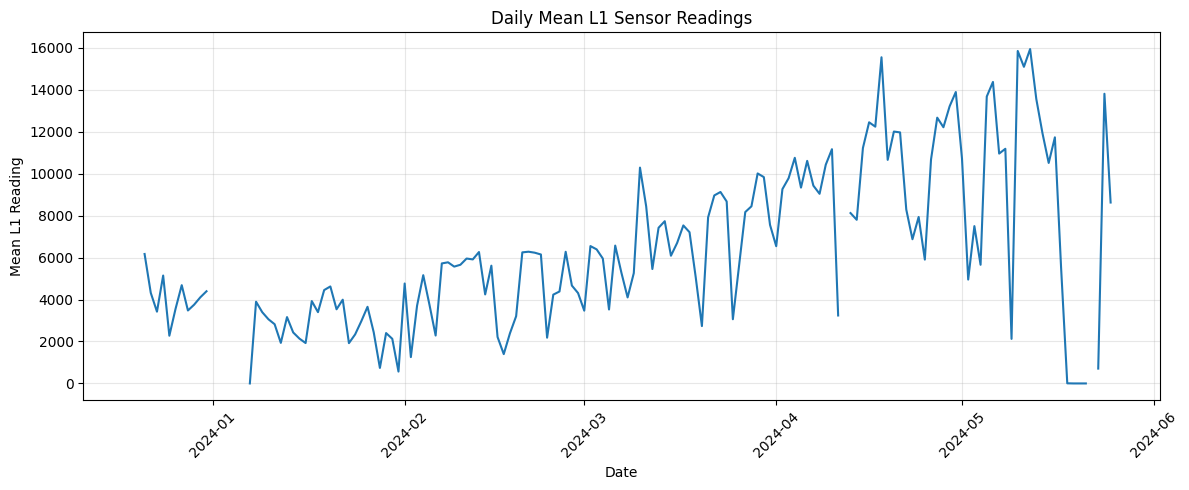

In [13]:
import matplotlib.pyplot as plt
# Graph-Daily Mean L1 Trend
daily_mean = df.set_index("DateTime")["L1"].resample("D").mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_mean.index, daily_mean.values)
plt.title("Daily Mean L1 Sensor Readings")
plt.xlabel("Date")
plt.ylabel("Mean L1 Reading")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

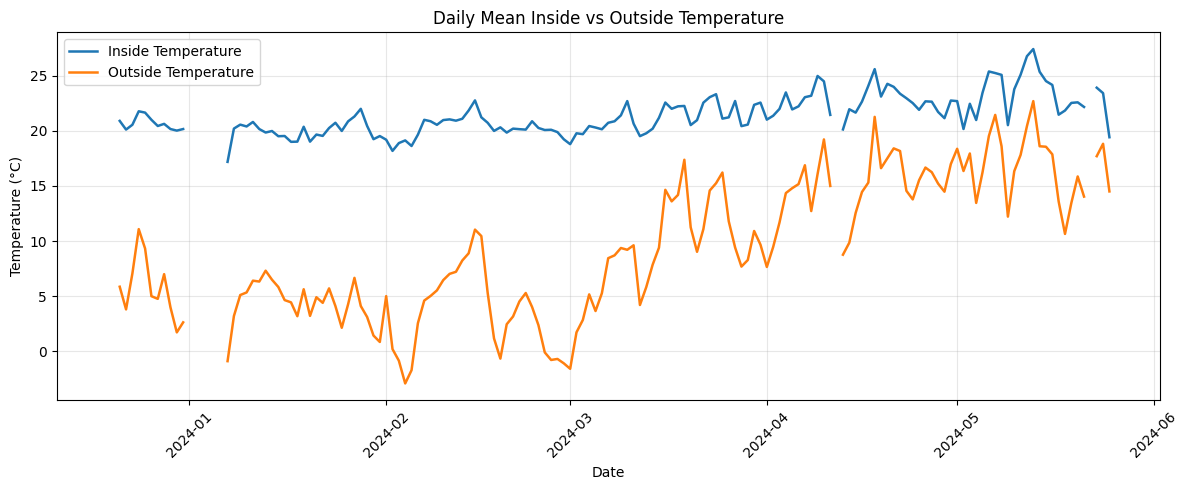

In [14]:
import matplotlib.pyplot as plt

daily_temp = df.set_index("DateTime")[
    ["MeanInsideTemp", "OutsideTemp"]
].resample("D").mean()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_temp.index,
    daily_temp["MeanInsideTemp"],
    label="Inside Temperature",
    linewidth=1.8
)

plt.plot(
    daily_temp.index,
    daily_temp["OutsideTemp"],
    label="Outside Temperature",
    linewidth=1.8
)

plt.title("Daily Mean Inside vs Outside Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Figure_2_Inside_vs_Outside_Temperature.png", dpi=300)
plt.show()

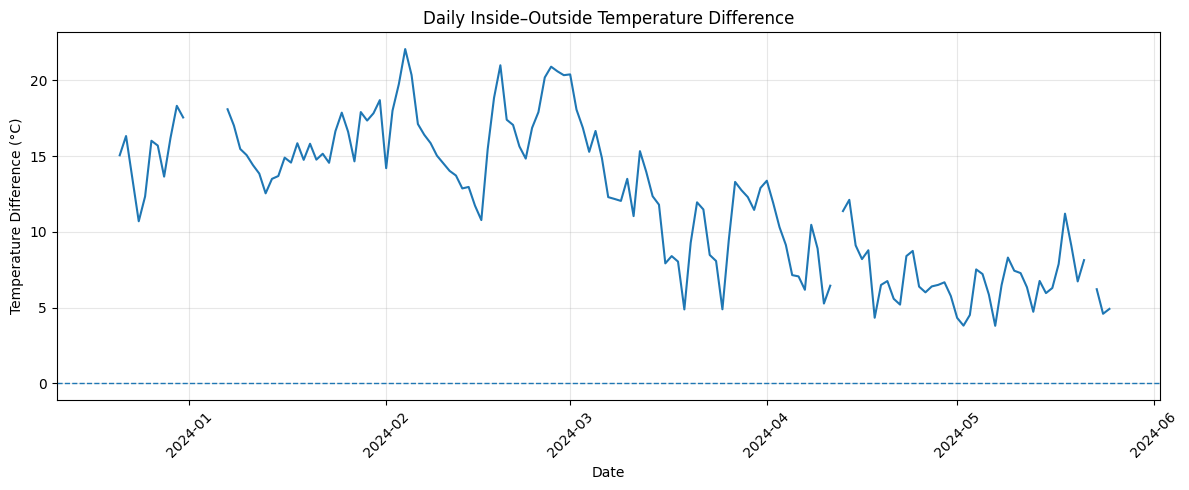

In [15]:
import matplotlib.pyplot as plt
# Temperature Difference
daily_temp = df.set_index("DateTime")[
    ["MeanInsideTemp", "OutsideTemp"]
].resample("D").mean()

daily_temp["Temperature_Difference"] = (
    daily_temp["MeanInsideTemp"] - daily_temp["OutsideTemp"]
)

plt.figure(figsize=(12, 5))
plt.plot(
    daily_temp.index,
    daily_temp["Temperature_Difference"],
    linewidth=1.5
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Daily Inside–Outside Temperature Difference")
plt.xlabel("Date")
plt.ylabel("Temperature Difference (°C)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Figure_3_Temperature_Difference.png", dpi=300)
plt.show()

In [16]:
diff = daily_temp["Temperature_Difference"].dropna()

print("Minimum difference:", round(diff.min(), 2), "°C")
print("Maximum difference:", round(diff.max(), 2), "°C")
print("Average difference:", round(diff.mean(), 2), "°C")
print("Zero or negative days:", (diff <= 0).sum())
print("Positive days:", (diff > 0).sum())

Minimum difference: 3.8 °C
Maximum difference: 22.06 °C
Average difference: 12.13 °C
Zero or negative days: 0
Positive days: 150


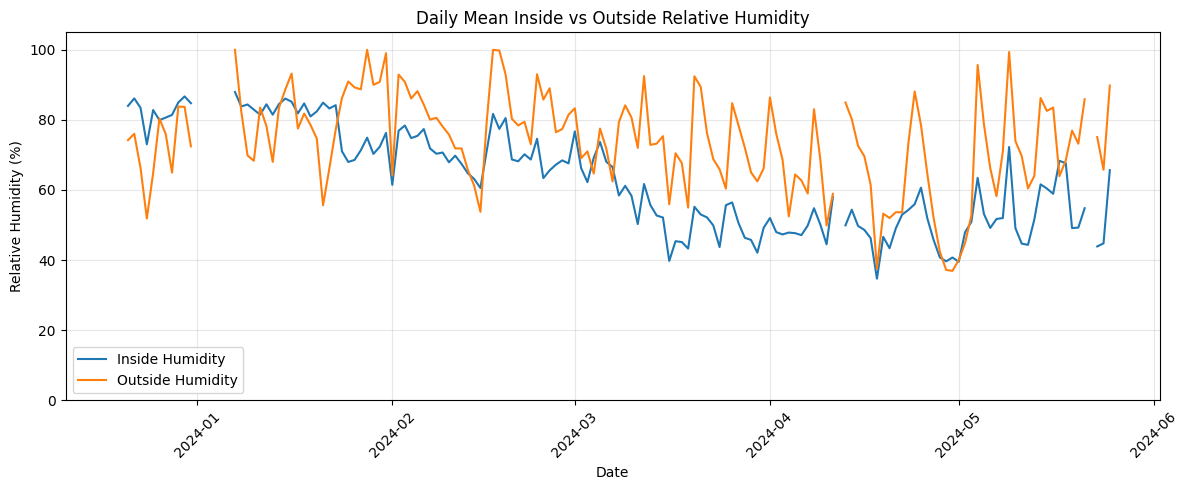

In [17]:
daily_humidity = df.set_index("DateTime")[
    ["AVGHumidityInside", "HumidityOutside"]
].resample("D").mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_humidity.index, daily_humidity["AVGHumidityInside"],
         label="Inside Humidity", linewidth=1.5)

plt.plot(daily_humidity.index, daily_humidity["HumidityOutside"],
         label="Outside Humidity", linewidth=1.5)

plt.title("Daily Mean Inside vs Outside Relative Humidity")
plt.xlabel("Date")
plt.ylabel("Relative Humidity (%)")
plt.ylim(0, 105)
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Figure_4_Inside_vs_Outside_Humidity.png", dpi=300)
plt.show()

In [18]:
humidity_diff = (
    daily_humidity["HumidityOutside"]
    - daily_humidity["AVGHumidityInside"]
).dropna()

print("Mean inside humidity:",
      round(daily_humidity["AVGHumidityInside"].mean(), 2), "%")

print("Mean outside humidity:",
      round(daily_humidity["HumidityOutside"].mean(), 2), "%")

print("Mean outside-inside difference:",
      round(humidity_diff.mean(), 2), "percentage points")

print("Days outside humidity was higher:",
      (humidity_diff > 0).sum())

print("Days inside humidity was higher:",
      (humidity_diff < 0).sum())

print("Days with equal humidity:",
      (humidity_diff == 0).sum())

Mean inside humidity: 62.99 %
Mean outside humidity: 73.95 %
Mean outside-inside difference: 10.95 percentage points
Days outside humidity was higher: 119
Days inside humidity was higher: 31
Days with equal humidity: 0


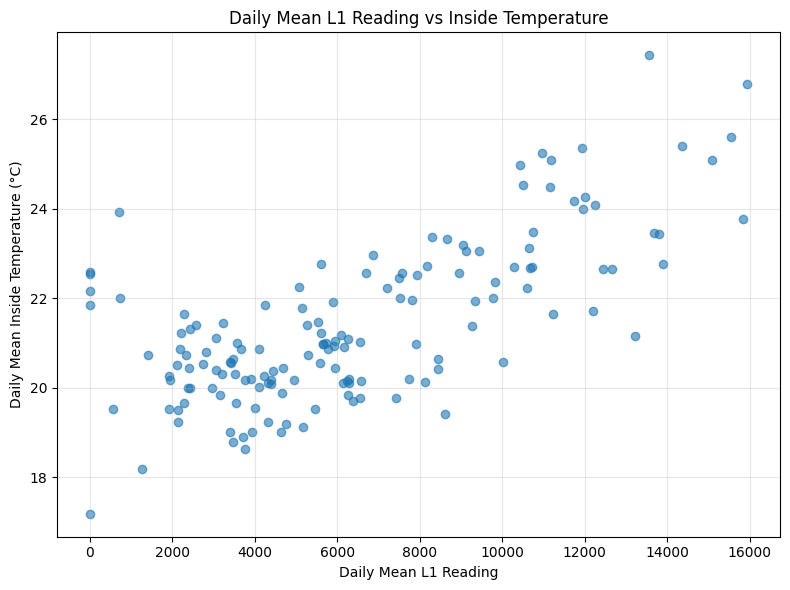

In [19]:
daily_light_temp = df.set_index("DateTime")[
    ["L1", "MeanInsideTemp"]
].resample("D").mean().dropna()

plt.figure(figsize=(8, 6))

plt.scatter(
    daily_light_temp["L1"],
    daily_light_temp["MeanInsideTemp"],
    alpha=0.6
)

plt.title("Daily Mean L1 Reading vs Inside Temperature")
plt.xlabel("Daily Mean L1 Reading")
plt.ylabel("Daily Mean Inside Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Figure_5_L1_vs_Inside_Temperature.png", dpi=300)
plt.show()

In [20]:
corr = daily_light_temp[
    ["L1", "MeanInsideTemp"]
].corr(method="pearson")

print("Pearson correlation:")
print(round(corr.loc["L1", "MeanInsideTemp"], 4))

print("\nNumber of daily observations:")
print(len(daily_light_temp))

Pearson correlation:
0.6955

Number of daily observations:
150


In [21]:
from scipy.stats import pearsonr

r, p_value = pearsonr(
    daily_light_temp["L1"],
    daily_light_temp["MeanInsideTemp"]
)

print("Pearson r:", round(r, 4))
print("P-value:", p_value)

Pearson r: 0.6955
P-value: 5.2504327198696337e-23


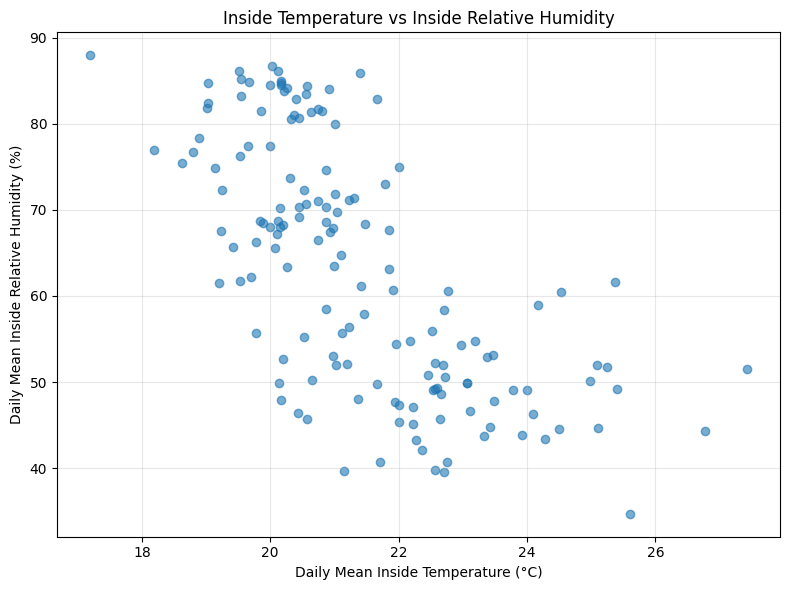

In [22]:
daily_temp_humidity = df.set_index("DateTime")[
    ["MeanInsideTemp", "AVGHumidityInside"]
].resample("D").mean().dropna()

plt.figure(figsize=(8, 6))

plt.scatter(
    daily_temp_humidity["MeanInsideTemp"],
    daily_temp_humidity["AVGHumidityInside"],
    alpha=0.6
)

plt.title("Inside Temperature vs Inside Relative Humidity")
plt.xlabel("Daily Mean Inside Temperature (°C)")
plt.ylabel("Daily Mean Inside Relative Humidity (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Figure_6_Inside_Temperature_vs_Humidity.png", dpi=300)
plt.show()

In [23]:
from scipy.stats import pearsonr

r, p = pearsonr(
    daily_temp_humidity["MeanInsideTemp"],
    daily_temp_humidity["AVGHumidityInside"]
)

print("Pearson r:", round(r, 4))
print("P-value:", p)
print("Observations:", len(daily_temp_humidity))

Pearson r: -0.6683
P-value: 9.309557163536071e-21
Observations: 150


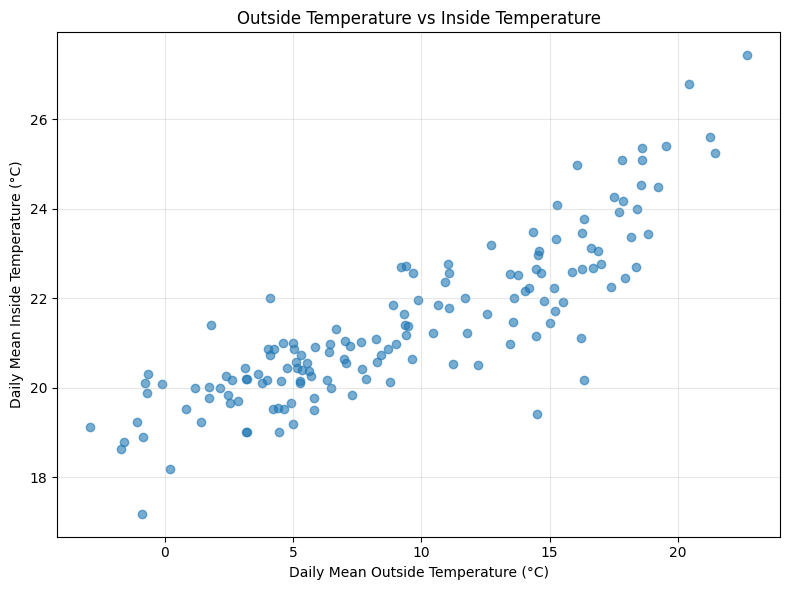

In [24]:
# Outside temparature vs inside temperature
daily_inside_outside = df.set_index("DateTime")[
    ["OutsideTemp", "MeanInsideTemp"]
].resample("D").mean().dropna()

plt.figure(figsize=(8, 6))
plt.scatter(
    daily_inside_outside["OutsideTemp"],
    daily_inside_outside["MeanInsideTemp"],
    alpha=0.6
)

plt.title("Outside Temperature vs Inside Temperature")
plt.xlabel("Daily Mean Outside Temperature (°C)")
plt.ylabel("Daily Mean Inside Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("Figure_7_Outside_vs_Inside_Temperature.png", dpi=300)
plt.show()

In [25]:
from scipy.stats import pearsonr

r, p = pearsonr(
    daily_inside_outside["OutsideTemp"],
    daily_inside_outside["MeanInsideTemp"]
)

print("Pearson r:", round(r, 4))
print("P-value:", p)
print("Observations:", len(daily_inside_outside))

Pearson r: 0.8591
P-value: 6.784803835228889e-45
Observations: 150


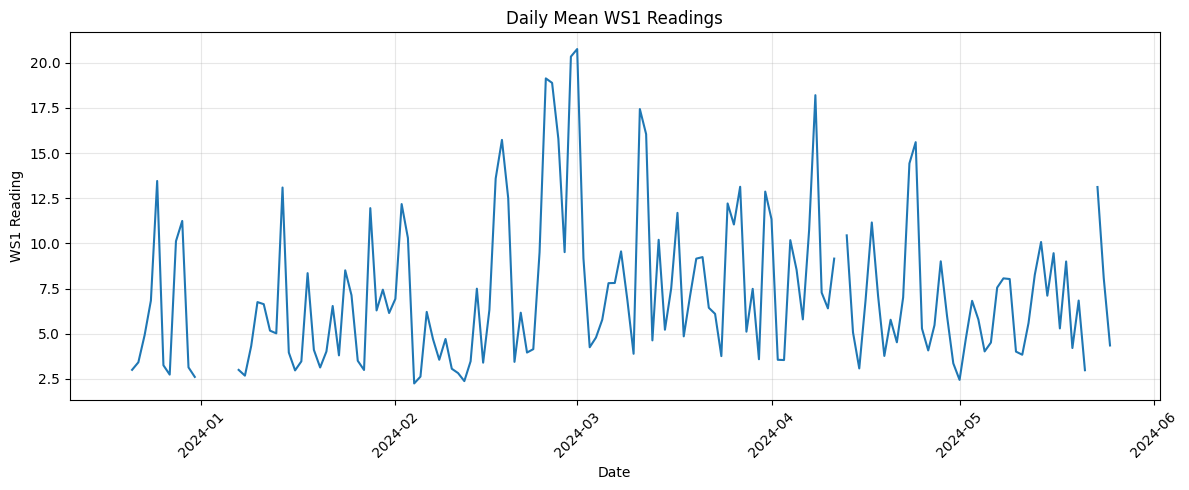

In [26]:
# Daily Mean Wind speed
daily_ws = df.set_index("DateTime")["WS1"].resample("D").mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_ws.index, daily_ws.values, linewidth=1.5)

plt.title("Daily Mean WS1 Readings")
plt.xlabel("Date")
plt.ylabel("WS1 Reading")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Figure_8_Daily_Mean_WS1.png", dpi=300)
plt.show()

In [27]:
# WS1-descriptive statistics
print("WS1 Statistical Summary:")
display(df["WS1"].describe().to_frame().T.round(3))

print("Daily WS1 Summary:")
display(daily_ws.describe().to_frame().T.round(3))

WS1 Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
WS1,130194.0,7.186,7.003,0.0,2.0,4.0,9.0,87.0


Daily WS1 Summary:


,count,mean,std,min,25%,50%,75%,max
WS1,150.0,7.239,4.122,2.25,4.014,6.31,9.229,20.762


In [28]:

monthly_temp = df.set_index("DateTime")[
    ["MeanInsideTemp", "OutsideTemp"]
].resample("MS").mean()

display(monthly_temp.round(2))

,MeanInsideTemp,OutsideTemp
DateTime,,
2023-12-01,20.70,5.37
2024-01-01,20.09,4.47
2024-02-01,20.30,3.52
2024-03-01,21.12,8.92
2024-04-01,22.71,14.86
2024-05-01,23.53,16.98


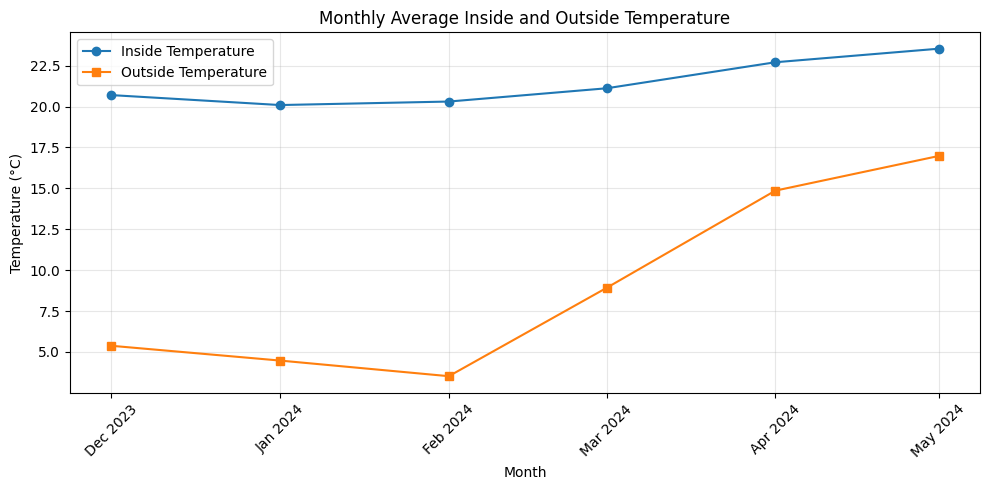

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_temp.index, monthly_temp["MeanInsideTemp"],
         marker="o", label="Inside Temperature")

plt.plot(monthly_temp.index, monthly_temp["OutsideTemp"],
         marker="s", label="Outside Temperature")

plt.title("Monthly Average Inside and Outside Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(monthly_temp.index, monthly_temp.index.strftime("%b %Y"),
           rotation=45)
plt.tight_layout()

plt.savefig("Figure_9_Monthly_Temperature_Comparison.png", dpi=300)
plt.show()

In [30]:
monthly_humidity = df.set_index("DateTime")[
    ["AVGHumidityInside", "HumidityOutside"]
].resample("MS").mean()

display(monthly_humidity.round(2))

,AVGHumidityInside,HumidityOutside
DateTime,,
2023-12-01,82.72,73.38
2024-01-01,79.04,81.99
2024-02-01,70.81,80.39
2024-03-01,56.04,72.82
2024-04-01,48.72,62.47
2024-05-01,53.80,71.36


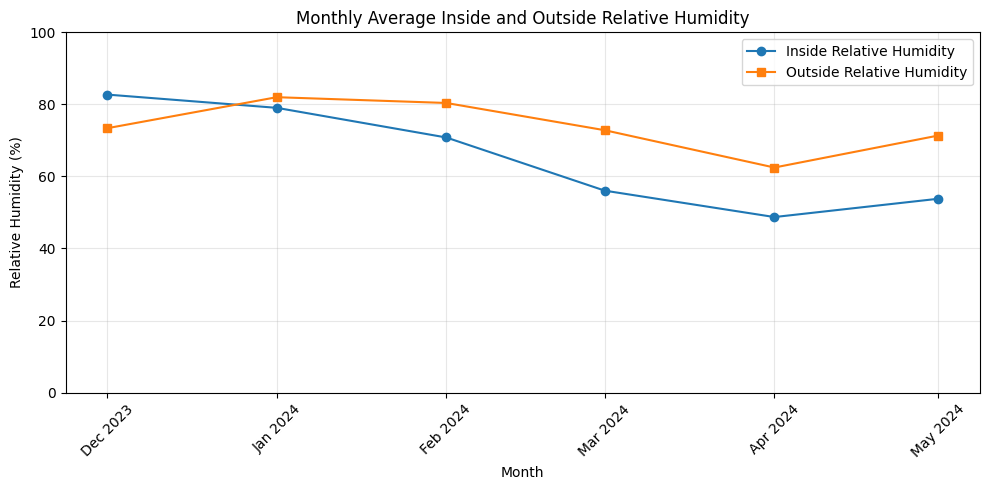

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_humidity.index,
         monthly_humidity["AVGHumidityInside"],
         marker="o", label="Inside Relative Humidity")

plt.plot(monthly_humidity.index,
         monthly_humidity["HumidityOutside"],
         marker="s", label="Outside Relative Humidity")

plt.title("Monthly Average Inside and Outside Relative Humidity")
plt.xlabel("Month")
plt.ylabel("Relative Humidity (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(monthly_humidity.index,
           monthly_humidity.index.strftime("%b %Y"),
           rotation=45)
plt.tight_layout()

plt.savefig("Figure_10_Monthly_Humidity_Comparison.png", dpi=300)
plt.show()

In [32]:
print("All column names:")
for i, col in enumerate(df.columns, 1):
    print(i, col)

print("\nFirst 5 rows of coded variables:")
display(df[[
    "F1", "F2", "F3", "F4",
    "H1", "H2", "H3", "H4",
    "W1", "W2", "W3", "W4",
    "L1", "WS1"
]].head())

All column names:
1 Unnamed: 0
2 F1
3 F2
4 F3
5 F4
6 H1
7 H10
8 H11
9 H12
10 H2
11 H3
12 H4
13 H5
14 H6
15 H7
16 H8
17 H9
18 W1
19 W10
20 W11
21 W12
22 W16
23 W2
24 W3
25 W4
26 W5
27 W6
28 W7
29 W8
30 W9
31 AVGHumidityInside
32 HumidityOutside
33 L1
34 MeanInsideTemp
35 OutsideTemp
36 WS1
37 DateTime

First 5 rows of coded variables:


,F1,F2,F3,F4,H1,H2,H3,H4,W1,W2,W3,W4,L1,WS1
0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0
1,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0
2,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,4.0
3,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0
4,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0


In [33]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

/content/Figure_4_Inside_vs_Outside_Humidity.png
/content/Figure_8_Daily_Mean_WS1.png
/content/greenhouse_dataset.csv
/content/Figure_3_Temperature_Difference.png
/content/Figure_6_Inside_Temperature_vs_Humidity.png
/content/Figure_9_Monthly_Temperature_Comparison.png
/content/Figure_5_L1_vs_Inside_Temperature.png
/content/Figure_10_Monthly_Humidity_Comparison.png
/content/Figure_7_Outside_vs_Inside_Temperature.png
/content/Figure_2_Inside_vs_Outside_Temperature.png
/content/.config/active_config
/content/.config/default_configs.db
/content/.config/.last_update_check.json
/content/.config/gce
/content/.config/config_sentinel
/content/.config/.last_survey_prompt.yaml
/content/.config/.last_opt_in_prompt.yaml
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/configurations/config_default
/content/.config/logs/2026.10.26/22.18.44.768076.log
/content/.config/logs/2026.10.26/22.18.53.588181.log
/content/.config/logs/2026.10.26/22.18.45.880512.l